# Quantum warm start vs. basic MILP: the results

Our solution is [`quantum_warm_start_milp.py`](../scheduling/quantum_warm_start_milp.py) (explained in [`QUANTUM_WARM_START.md`](../docs/QUANTUM_WARM_START.md)):

1. QAOA samples block-level on/off schedules from a QUBO (plants × K time blocks = qubits).
2. A classical **repair** step makes the best samples obey every rule.
3. The cheapest repaired schedule is handed to HiGHS as its **starting solution** (MIP warm start). HiGHS then proves the true optimum.

This notebook answers the judges' checklist with our own numbers:

| Question | Section |
|---|---|
| Daily cost against the exact baseline and the cheapest-first rule | 2, 4 |
| How often our answers were valid (QAOA vs random guessing, across shots and seeds) | 3 |
| Rules broken, and what repair fixes | 4, 5 |
| Warm-started MILP vs basic (cold) MILP: time, nodes, primal-dual integral | 6 |
| Hardware result next to the simulator, with job IDs | 7 |
| Honest summary | 8 |

**Kernel:** qBraid-SDK (v0.12.2). The MILP solver's package, `highspy`, is installed into the kernel's environment automatically the first time the pipeline is imported, if it's missing. Run top to bottom; everything except section 7's device jobs takes about 3 minutes.

**Every rule check in this notebook uses the official `check.check_schedule`**, not our own checker, so "valid" means the same thing as in the starter notebook.

## 1. Setup

The switches below control the quantum-device runs in section 7. Results are cached in `../outputs/warm_start_results/hardware_runs.json`, so re-running the notebook never resubmits a job that already finished.

- `RUN_NOISY_SIM`: IonQ's simulator with the Forte-1 noise model. **Free.**
- `RUN_H2_EMULATOR`: Quantinuum's H2 emulator. Free, but accept Quantinuum's terms under Devices first. It is an emulator, not hardware.
- `RUN_QPU`: the real IonQ Forte QPU. **Paid**: about 30 credits per task + 8 per shot (200 shots ≈ 1,630 credits = $16.30 on `aws:ionq:qpu:forte-1`). The cell refuses to submit if the estimate is above `MAX_CREDITS`. Check `qbraid account credits` first.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # same as the script: faster small-matrix QAOA simulation
import json, math, time, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scheduling' / 'check.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT / 'scheduling'))
import check                              # the official checker and scipy MILP baseline
import quantum_warm_start_milp as qw      # our solution

OUT = PROJECT_ROOT / 'outputs' / 'warm_start_results'; OUT.mkdir(parents=True, exist_ok=True)
SEED = 0
REPEATS = 5              # HiGHS runs per mode (different seeds); medians are reported

# ---- section 7: quantum devices
RUN_NOISY_SIM   = True                    # free
RUN_H2_EMULATOR = False                   # free, needs Quantinuum terms accepted
RUN_QPU         = False                   # PAID: switch on only after agreeing on the cost
QPU_DEVICE      = "aws:ionq:qpu:forte-1"  # ionq:ionq:qpu:forte-1 if it is ONLINE
MAX_CREDITS     = 0                       # e.g. 1700 for 200 shots; 0 = refuse any paid job
HW_SHOTS        = 200                     # hardware rule: at most 200 shots
WAIT_S          = 900                     # how long a cell waits for a job before moving on

# one color per method, the same in every chart
COLORS = {"milp": "#2a78d6", "rule": "#eb6834", "warm": "#1baf7a", "random": "#eda100",
          "raw": "#e87ba4", "noisy": "#008300", "qpu": "#6250d6", "h2": "#e34948"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

plants = qw.load_plants(PROJECT_ROOT / 'data' / 'plants.csv')
demand, reserve = qw.load_demand(PROJECT_ROOT / 'data' / 'demand.csv')
T, n = len(demand), len(plants)
model = qw.Milp(plants, demand, reserve)
names = [p["plant_id"] for p in plants]
print(f"{n} plants x {T} hours -> MILP with {model.N} variables ({2 * n * T} binary), {model.A.shape[0]} constraints")

5 plants x 24 hours -> MILP with 360 variables (240 binary), 648 constraints


### Helpers

Small wrappers around the script's functions. `run_highs` is the script's HiGHS call plus the full incumbent timeline. `train_qaoa` is the exact training step inside `qw.solve_qaoa` (same start angles, COBYLA, CVaR), split out so we keep the trained circuit and can measure it on any backend and count every shot.

In [2]:
import highspy

def run_highs(model, start=None, time_limit=60.0, seed=0):
    """qw.run_highs, plus the timeline of improving solutions [(seconds, cost), ...]."""
    h = highspy.Highs()
    h.setOptionValue("output_flag", False)
    h.setOptionValue("time_limit", float(time_limit))
    h.setOptionValue("random_seed", int(seed))
    h.setOptionValue("threads", 1)
    h.passModel(model.to_highs())
    timeline, t0 = [], [0.0]
    h.cbMipImprovingSolution.subscribe(
        lambda e: timeline.append((time.perf_counter() - t0[0], float(e.data_out.objective_function_value))))
    if start is not None:
        sol = highspy.HighsSolution()
        sol.col_value = list(map(float, start))
        sol.value_valid = True
        h.setSolution(sol)
    t0[0] = time.perf_counter()
    h.run()
    secs = time.perf_counter() - t0[0]
    info = h.getInfo()
    return {"status": h.modelStatusToString(h.getModelStatus()), "seconds": secs,
            "objective": info.objective_function_value, "nodes": int(info.mip_node_count),
            "gap_pct": 100 * info.mip_gap, "pdi": info.primal_dual_integral,
            "timeline": timeline, "x": np.array(h.getSolution().col_value)}


def schedule_from_x(model, x):
    return np.round(x[:model.n * model.T]).reshape(model.n, model.T).T.astype(int)


def score(plants, demand, reserve, S, milp_cost):
    """Official checker: cost, gap, list of broken rules."""
    return check.check_schedule(plants, demand, reserve, np.asarray(S), milp_cost=milp_cost, verbose=False)


def cheapest_first(plants, demand, reserve, starter_version=False):
    """TODO 1 of the starter: rank by cost per MWh at full output, switch on down the list until
    capacity >= demand + reserve. starter_version=True reproduces starter.ipynb's ranking
    (marginal + no_load) / pmax, which differs from the README's marginal + no_load / pmax."""
    if starter_version:
        key = [(p["marginal_cost_per_mwh"] + p["no_load_cost_per_h"]) / p["pmax_mw"] for p in plants]
    else:
        key = [p["marginal_cost_per_mwh"] + p["no_load_cost_per_h"] / p["pmax_mw"] for p in plants]
    order = np.argsort(key)
    S = np.zeros((len(demand), len(plants)), int)
    for t in range(len(demand)):
        cap = 0.0
        for i in order:
            if cap >= demand[t] + reserve[t]:
                break
            S[t, i] = 1
            cap += plants[i]["pmax_mw"]
    return S


def train_qaoa(qubo, p, alpha=0.25, maxiter=60):
    """Exactly the training inside qw.solve_qaoa: CVaR objective on the numpy statevector, linear-ramp start."""
    E = qubo.all_energies()
    shift, scale = E.mean(), E.std()
    Ehat = (E - shift) / scale
    order = np.argsort(E)
    E_sorted = Ehat[order]

    def cvar(probs):
        ps = probs[order]
        cum = np.cumsum(ps)
        cut = np.searchsorted(cum, alpha)
        tot = ps[:cut] @ E_sorted[:cut] + (alpha - (cum[cut - 1] if cut else 0.0)) * E_sorted[min(cut, len(ps) - 1)]
        return tot / alpha

    obj = lambda th: cvar(np.abs(qw.qaoa_state(Ehat, th[:p], th[p:], qubo.N)) ** 2)
    x0 = np.r_[np.linspace(0.1, 0.8, p), np.linspace(0.8, 0.1, p)]
    t0 = time.perf_counter()
    res = minimize(obj, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.3})
    probs = np.abs(qw.qaoa_state(Ehat, res.x[:p], res.x[p:], qubo.N)) ** 2
    return {"E": E, "shift": shift, "scale": scale, "gammas": res.x[:p], "betas": res.x[p:],
            "cvar": res.fun, "cvar_uniform": cvar(np.full(2 ** qubo.N, 2.0 ** -qubo.N)),
            "probs": probs / probs.sum(), "nfev": res.nfev, "seconds": time.perf_counter() - t0}


def measured_circuit(qubo, tr):
    qc = qw.qaoa_circuit(qubo, tr["scale"], tr["shift"], tr["gammas"], tr["betas"])
    qc.measure_all()
    return qc


def sample_aer(qc, shots, seed=0):
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    sim = AerSimulator(seed_simulator=seed)
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    return {int(s.replace(" ", ""), 2): c for s, c in counts.items()}     # qubit 0 = rightmost


def sample_probs(probs, shots, seed=0):
    zs, cs = np.unique(np.random.default_rng(seed).choice(len(probs), size=shots, p=probs), return_counts=True)
    return dict(zip(zs.tolist(), cs.tolist()))


def sample_uniform(N, shots, seed=0):
    zs, cs = np.unique(np.random.default_rng(seed).integers(0, 2 ** N, shots), return_counts=True)
    return dict(zip(zs.tolist(), cs.tolist()))


def analyze(counts, qubo, model, E, milp_cost, candidates=50):
    """Everything we report about one set of measured bitstrings.

    raw_valid   share of shots whose block schedule already passes check_schedule (no repair)
    repairable  share of shots that repair turns into a valid schedule
    p_opt       share of shots that hit the QUBO's own optimum
    warm start  the cheapest valid schedule after repairing the `candidates` lowest-energy samples
    """
    pl, dm, rs = model.plants, model.demand, model.reserve
    shots = sum(counts.values())
    raw_valid = repairable = 0
    for z, c in counts.items():
        S0 = qubo.to_schedule(qw.bits_of(z, qubo.N), model.T)
        raw_valid += c * score(pl, dm, rs, S0, milp_cost)["valid"]
        repairable += c * (qw.repair(model, S0) is not None)
    by_energy = sorted(counts, key=lambda z: E[z])
    best_S, best_cost = None, math.inf
    for z in by_energy[:candidates]:
        S = qw.repair(model, qubo.to_schedule(qw.bits_of(z, qubo.N), model.T))
        if S is not None and (c := qw.true_cost(model, S)) < best_cost:
            best_S, best_cost = S, c
    Ehat = (E - E.mean()) / E.std()
    e_shots = np.repeat([Ehat[z] for z in counts], list(counts.values()))
    return {"shots": shots, "distinct": len(counts),
            "p_opt": sum(c for z, c in counts.items() if E[z] <= E.min() + 1e-9) / shots,
            "raw_valid": raw_valid / shots, "repairable": repairable / shots,
            "cvar25": float(np.sort(e_shots)[:max(1, int(0.25 * shots))].mean()),
            "low5": sum(c for z, c in counts.items() if E[z] <= np.quantile(E, 0.05)) / shots,
            "mean_energy": float(e_shots.mean()),
            "raw_S": qubo.to_schedule(qw.bits_of(by_energy[0], qubo.N), model.T),
            "warm_S": best_S, "warm_cost": best_cost,
            "warm_gap": 100 * (best_cost - milp_cost) / milp_cost if best_S is not None else math.nan}

print("helpers ready")

helpers ready


## 2. The two classical baselines

- **Exact MILP ("basic MILP")**: HiGHS on the full model with no starting solution. This is what a utility uses today. We also run the starter's scipy `solve_milp` as a cross-check: same cost.
- **Cheapest-first rule** (TODO 1): rank plants by cost per MWh at full output, `marginal + no_load / pmax`, and switch on down the list each hour until capacity covers demand + reserve. It ignores startup costs and min up/down times.

Note: `starter.ipynb`'s TODO 1 computes `(marginal + no_load) / pmax`, which ranks GAS_CC ahead of COAL. We show both versions so the numbers line up with whichever one is quoted.

In [3]:
cold0 = run_highs(model, None, seed=SEED)
MILP_COST = cold0["objective"]
milp_S = schedule_from_x(model, cold0["x"])
scipy_cost, _, _, scipy_secs = check.solve_milp(plants, demand, reserve)

rule_S = cheapest_first(plants, demand, reserve)
rule_starter_S = cheapest_first(plants, demand, reserve, starter_version=True)
milp_r, rule_r, rule_starter_r = (score(plants, demand, reserve, S, MILP_COST) for S in (milp_S, rule_S, rule_starter_S))
RULE_COST = rule_r["total_cost"]

print(f"Exact MILP (HiGHS, cold): ${MILP_COST:,.0f} in {cold0['seconds']:.3f} s, {cold0['nodes']} B&B node(s), {cold0['status']}")
print(f"Exact MILP (scipy, check.solve_milp): ${scipy_cost:,.0f} in {scipy_secs:.3f} s")
print(f"MILP schedule passes check_schedule: {milp_r['valid']}\n")
for label, r in [("Cheapest-first rule (README ranking)", rule_r), ("Cheapest-first rule (starter.ipynb ranking)", rule_starter_r)]:
    print(f"{label}: ${r['total_cost']:,.0f}, gap {r['gap_pct']:+.2f}%, {len(r['violations'])} rule(s) broken")
    for t, pid, rule, detail in r["violations"]:
        print(f"    hour {t:>2}  {pid:<9} {rule:<16} {detail}")

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Exact MILP (HiGHS, cold): $327,924 in 0.032 s, 1 B&B node(s), Optimal
Exact MILP (scipy, check.solve_milp): $327,924 in 0.036 s
MILP schedule passes check_schedule: True

Cheapest-first rule (README ranking): $330,594, gap +0.81%, 1 rule(s) broken
    hour 16  PEAKER_B  min up broken    turned off after 2 h on (needs 3)
Cheapest-first rule (starter.ipynb ranking): $373,168, gap +13.80%, 2 rule(s) broken
    hour  5  COAL      min down broken  restarted after 5 h off (needs 48)
    hour 16  PEAKER_B  min up broken    turned off after 2 h on (needs 3)


## 3. The quantum step on the simulator, and how often its answers are valid

5 plants × 4 blocks = **20 qubits**, QAOA with p = 2 layers, angles trained on the statevector, then 4,000 shots of the Qiskit circuit on Aer.

For every shot we ask two questions with the official checker:

- **Valid as sampled?** Does the raw block schedule already obey every rule (demand, reserve, min up/down)?
- **Valid after repair?** Can the repair step turn it into a legal schedule?

The control is **uniform random guessing**: the same number of random bitstrings, through exactly the same repair and selection. If random + repair does as well as QAOA + repair, then repair, not QAOA, is doing the work.

In [4]:
K5 = 4
blocks5 = qw.split_into_blocks(demand + reserve, K5)
qubo5 = qw.Qubo(plants, demand, reserve, blocks5)
tr5 = train_qaoa(qubo5, p=2)
print(f"Blocks: {[f'{h[0]}-{h[-1]}' for h in blocks5]} -> {qubo5.N} qubits")
print(f"QAOA p=2 trained in {tr5['seconds']:.1f} s ({tr5['nfev']} statevector simulations): "
      f"CVaR(0.25) {tr5['cvar']:+.3f} vs {tr5['cvar_uniform']:+.3f} for random guessing (lower is better)")

t0 = time.perf_counter()
qaoa_counts = sample_aer(measured_circuit(qubo5, tr5), shots=4000, seed=SEED)
aer_secs = time.perf_counter() - t0
rand_counts = sample_uniform(qubo5.N, 4000, seed=SEED)
t0 = time.perf_counter()
qa = analyze(qaoa_counts, qubo5, model, tr5["E"], MILP_COST)
repair_secs = time.perf_counter() - t0
ra = analyze(rand_counts, qubo5, model, tr5["E"], MILP_COST)

print(f"\n{'4,000 shots':<26}{'QAOA (Aer)':>14}{'random':>14}")
for key, label, fmt in [("distinct", "distinct bitstrings", "{:,.0f}"), ("p_opt", "hit the QUBO optimum", "{:.3%}"),
                        ("raw_valid", "valid as sampled", "{:.1%}"), ("repairable", "valid after repair", "{:.1%}"),
                        ("cvar25", "CVaR(0.25) of shots", "{:+.3f}"), ("warm_gap", "best warm start gap", "{:+.2f}%")]:
    print(f"{label:<26}{fmt.format(qa[key]):>14}{fmt.format(ra[key]):>14}")
print(f"\nchance of the QUBO optimum per random guess: {2.0 ** -qubo5.N:.5%}")

Blocks: ['0-6', '7-10', '11-17', '18-23'] -> 20 qubits
QAOA p=2 trained in 7.9 s (60 statevector simulations): CVaR(0.25) -2.400 vs -1.238 for random guessing (lower is better)



4,000 shots                   QAOA (Aer)        random
distinct bitstrings                3,718         3,995
hit the QUBO optimum              0.025%        0.000%
valid as sampled                    2.4%          0.1%
valid after repair                100.0%        100.0%
CVaR(0.25) of shots               -2.402        -1.252
best warm start gap               +1.12%        +1.12%

chance of the QUBO optimum per random guess: 0.00010%


### Across shots and seeds

One run of 4,000 shots can be lucky. Here we draw 5 to 1,000 shots from the trained QAOA distribution and from uniform random guessing, 10 seeds each, and run each set through the same repair → warm-start selection. Lines are medians, bands span min to max over seeds.

 shots |    valid as sampled     |  warm-start gap (median)  | hit QUBO optimum (seeds) 
       |       QAOA      random |        QAOA       random |        QAOA       random
     5 |       0.0%        0.0% |      +5.49%       +8.30% |        0/10         0/10
    10 |       0.0%        0.0% |      +4.61%       +7.58% |        0/10         0/10
    20 |       0.0%        0.0% |      +2.98%       +6.00% |        0/10         0/10
    50 |       1.0%        0.0% |      +2.54%       +4.57% |        0/10         0/10
   200 |       2.0%        0.0% |      +2.27%       +4.57% |        0/10         0/10
  1000 |       2.4%        0.1% |      +1.75%       +4.44% |        0/10         0/10


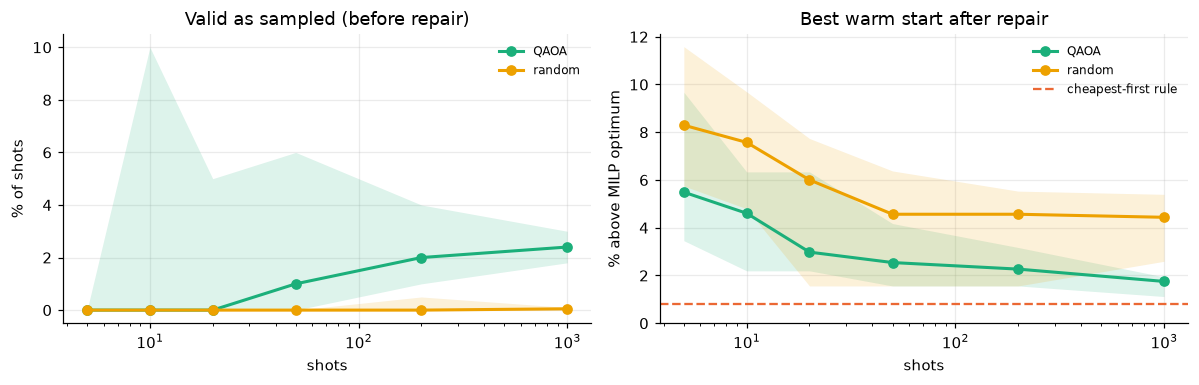

In [5]:
SHOT_LIST = [5, 10, 20, 50, 200, 1000]
SEEDS = range(10)
sweep = {"QAOA": {}, "random": {}}
for shots in SHOT_LIST:
    for name in sweep:
        rows = []
        for s in SEEDS:
            cnt = sample_probs(tr5["probs"], shots, s) if name == "QAOA" else sample_uniform(qubo5.N, shots, s)
            rows.append(analyze(cnt, qubo5, model, tr5["E"], MILP_COST))
        sweep[name][shots] = rows

print(f"{'shots':>6} | {'valid as sampled':^23} | {'warm-start gap (median)':^25} | {'hit QUBO optimum (seeds)':^25}")
print(f"{'':>6} | {'QAOA':>10} {'random':>11} | {'QAOA':>11} {'random':>12} | {'QAOA':>11} {'random':>12}")
for shots in SHOT_LIST:
    q_, r_ = sweep["QAOA"][shots], sweep["random"][shots]
    med = lambda rows, k: np.median([r[k] for r in rows])
    hit = lambda rows: sum(r["p_opt"] > 0 for r in rows)
    print(f"{shots:>6} | {med(q_, 'raw_valid'):>10.1%} {med(r_, 'raw_valid'):>11.1%} | "
          f"{med(q_, 'warm_gap'):>+10.2f}% {med(r_, 'warm_gap'):>+11.2f}% | {hit(q_):>8}/{len(SEEDS)} {hit(r_):>9}/{len(SEEDS)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, color in [("QAOA", COLORS["warm"]), ("random", COLORS["random"])]:
    for ax, key, scale_ in [(axes[0], "raw_valid", 100), (axes[1], "warm_gap", 1)]:
        vals = np.array([[r[key] * scale_ for r in sweep[name][s]] for s in SHOT_LIST])
        ax.fill_between(SHOT_LIST, vals.min(1), vals.max(1), color=color, alpha=0.15, lw=0)
        ax.plot(SHOT_LIST, np.median(vals, 1), "o-", color=color, lw=2, ms=6, label=name)
axes[0].set(xscale="log", xlabel="shots", ylabel="% of shots", title="Valid as sampled (before repair)")
axes[1].set(xscale="log", xlabel="shots", ylabel="% above MILP optimum", title="Best warm start after repair")
axes[1].axhline(100 * (RULE_COST - MILP_COST) / MILP_COST, color=COLORS["rule"], ls="--", lw=1.5, label="cheapest-first rule")
axes[1].set_ylim(bottom=0)
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 4. Daily cost against the exact baseline and the cheapest-first rule (5 plants)

The warm start is handed to HiGHS, which then returns the proven optimum. "Rules broken" counts every row of `check_schedule`'s violation table.

method                                    daily cost   vs MILP     vs rule  valid  rules broken
Exact MILP (basic, cold HiGHS)          $    327,924    +0.00%      -2,670    yes             0
Cheapest-first rule                     $    330,594    +0.81%          +0     NO             1
Cheapest-first (starter.ipynb ranking)  $    373,168   +13.80%     +42,574     NO             2
QAOA best sample, before repair         $    313,517    -4.39%     -17,077     NO             7
Random + repair (control)               $    331,596    +1.12%      +1,002    yes             0
QAOA + repair = our warm start          $    331,596    +1.12%      +1,002    yes             0
Warm-started HiGHS (final answer)       $    327,924    +0.00%      -2,670    yes             0

The warm start is $1,002/day more expensive than the cheapest-first rule (which is NOT valid), and $3,672/day (+1.12%) above the optimum before HiGHS finishes the job.
The raw QAOA sample looks cheaper than the optimum only because

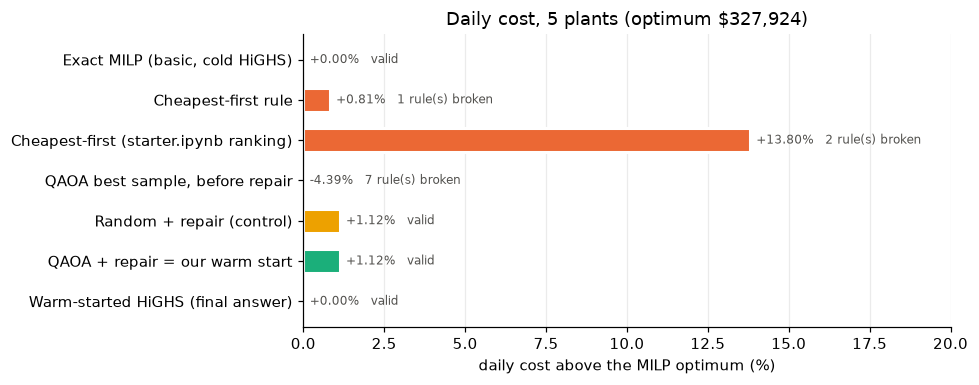

In [6]:
warm0 = run_highs(model, qw.full_solution(model, qa["warm_S"]), seed=SEED)
final_S = schedule_from_x(model, warm0["x"])

rows = [("Exact MILP (basic, cold HiGHS)", milp_S, "milp"),
        ("Cheapest-first rule", rule_S, "rule"),
        ("Cheapest-first (starter.ipynb ranking)", rule_starter_S, "rule"),
        ("QAOA best sample, before repair", qa["raw_S"], "raw"),
        ("Random + repair (control)", ra["warm_S"], "random"),
        ("QAOA + repair = our warm start", qa["warm_S"], "warm"),
        ("Warm-started HiGHS (final answer)", final_S, "milp")]
results = [(label, S, score(plants, demand, reserve, S, MILP_COST), c) for label, S, c in rows]

print(f"{'method':<40}{'daily cost':>12}{'vs MILP':>10}{'vs rule':>12}{'valid':>7}{'rules broken':>14}")
for label, _, r, _ in results:
    print(f"{label:<40}${r['total_cost']:>11,.0f}{r['gap_pct']:>+9.2f}%{r['total_cost'] - RULE_COST:>+12,.0f}"
          f"{'yes' if r['valid'] else 'NO':>7}{len(r['violations']):>14}")
diff = qa['warm_cost'] - RULE_COST
print(f"\nThe warm start is ${abs(diff):,.0f}/day {'cheaper' if diff < 0 else 'more expensive'} than the cheapest-first rule "
      f"(which is {'valid' if rule_r['valid'] else 'NOT valid'}), and ${qa['warm_cost'] - MILP_COST:,.0f}/day "
      f"({qa['warm_gap']:+.2f}%) above the optimum before HiGHS finishes the job.")
print("The raw QAOA sample looks cheaper than the optimum only because it breaks rules (not enough capacity on).")
print(f"Warm-started HiGHS final: {warm0['status']}, ${warm0['objective']:,.0f} (cold: ${MILP_COST:,.0f})")

raw_v = results[3][2]["violations"]
print(f"\nRules the raw QAOA sample breaks (what repair has to fix): {len(raw_v)}")
for t, pid, rule, detail in raw_v:
    print(f"    hour {t:>2}  {pid:<9} {rule:<16} {detail}")

fig, ax = plt.subplots(figsize=(9, 3.6))
labels = [l for l, _, _, _ in results]
gaps = [r["gap_pct"] for _, _, r, _ in results]
ax.barh(labels, gaps, color=[COLORS[c] for _, _, _, c in results], height=0.6, edgecolor="white", linewidth=2)
for y, (_, _, r, _) in enumerate(results):
    note = f"{r['gap_pct']:+.2f}%" + (f"   {len(r['violations'])} rule(s) broken" if r["violations"] else "   valid")
    ax.text(max(r["gap_pct"], 0) + 0.2, y, note, va="center", fontsize=8, color="#52514e")
ax.invert_yaxis()
ax.set_xlim(0, 1.45 * max(gaps))
ax.set(xlabel="daily cost above the MILP optimum (%)", title=f"Daily cost, 5 plants (optimum ${MILP_COST:,.0f})")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 5. Schedule viewer: every broken rule flagged

Filled cells = plant on. A red ✕ marks the hour and plant of a broken rule (hour-wide rules such as reserve sit on a row of their own). The raw QAOA sample is block-shaped because one qubit covers a whole block; repair adds the missing hours.

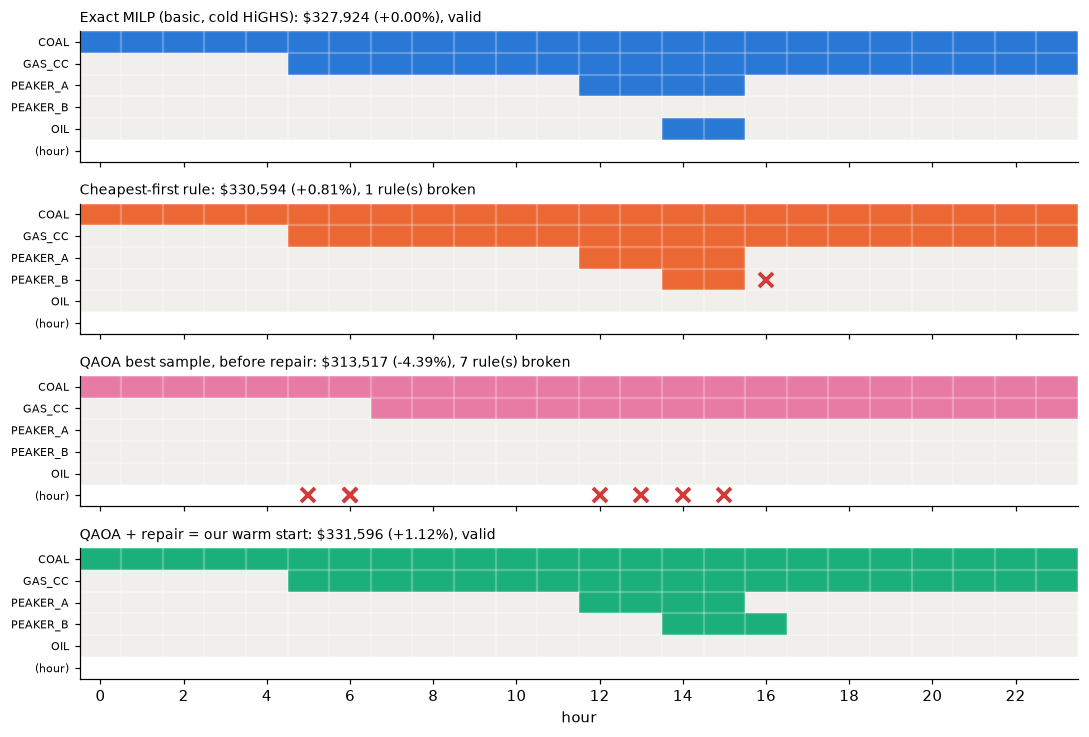

In [7]:
def plot_schedule(ax, S, r, title, color):
    from matplotlib.colors import ListedColormap
    ax.imshow(S.T, aspect="auto", cmap=ListedColormap(["#f0efec", color]), vmin=0, vmax=1, interpolation="none")
    ax.set_yticks(range(n + 1), names + ["(hour)"], fontsize=7)
    ax.set_xticks(range(0, T, 2)); ax.set_xticks(np.arange(-.5, T), minor=True)
    ax.set_yticks(np.arange(-.5, n + 1), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    ax.set_ylim(n + 0.5, -0.5)
    for t, pid, rule, detail in r["violations"]:
        row = names.index(pid) if pid in names else n
        ax.plot(t, row, "x", color="#d03b3b", ms=9, mew=2.5)
    status = "valid" if r["valid"] else f"{len(r['violations'])} rule(s) broken"
    ax.set_title(f"{title}: ${r['total_cost']:,.0f} ({r['gap_pct']:+.2f}%), {status}", fontsize=9, loc="left")

show = [results[0], results[1], results[3], results[5]]
fig, axes = plt.subplots(len(show), 1, figsize=(10, 1.55 * len(show) + 0.6), sharex=True)
for ax, (label, S, r, c) in zip(axes, show):
    plot_schedule(ax, np.asarray(S), r, label, COLORS[c])
axes[-1].set_xlabel("hour")
plt.tight_layout(); plt.show()

## 6. Warm-started MILP vs basic MILP, on bigger fleets

Same HiGHS, same model, same 1 thread, `REPEATS` seeds each. The only difference is whether HiGHS starts with our repaired schedule.

| Case | Fleet | Quantum step |
|---|---|---|
| 5 plants | `data/plants.csv` | QAOA p=2, 20 qubits (K=4), Aer, 4,000 shots |
| 10 plants | `data/plants10.csv` | QAOA p=2, 20 qubits (K=2), Aer, 4,000 shots |
| 20 plants | 5-plant fleet × 4, costs jittered ±8% | **simulated annealing** on 80 bits (too many qubits to simulate QAOA) |
| 40 plants | 5-plant fleet × 8 | **simulated annealing** on 160 bits |

For the two QAOA cases we also warm-start from **random + repair**, to see whether QAOA's start is any better than a random one.

Metrics: HiGHS time, branch-and-bound nodes, and the **primal-dual integral** (area under the gap-over-time curve: small when a good answer exists early and the gap closes fast). "End to end" adds the quantum step (simulation time, not QPU time) and repair to the warm HiGHS time.

In [8]:
def warm_start_from(qubo, model, cands, candidates=50):
    best_S, best_cost = None, math.inf
    for x in cands[:candidates]:
        S = qw.repair(model, qubo.to_schedule(x, model.T))
        if S is not None and (c := qw.true_cost(model, S)) < best_cost:
            best_S, best_cost = S, c
    return best_S, best_cost


def run_case(label, plants_c, demand_c, reserve_c, K, solver):
    m = qw.Milp(plants_c, demand_c, reserve_c)
    qb = qw.Qubo(plants_c, demand_c, reserve_c, qw.split_into_blocks(demand_c + reserve_c, K))
    t0 = time.perf_counter()
    starts = {}
    if solver == "qaoa":
        tr = train_qaoa(qb, p=2)
        cnt = sample_aer(measured_circuit(qb, tr), 4000, SEED)
        q_secs = time.perf_counter() - t0
        order = sorted(cnt, key=lambda z: tr["E"][z])
        starts["warm (QAOA)"] = warm_start_from(qb, m, [qw.bits_of(z, qb.N) for z in order])
        rnd = sample_uniform(qb.N, 4000, SEED)
        starts["warm (random)"] = warm_start_from(qb, m, [qw.bits_of(z, qb.N) for z in sorted(rnd, key=lambda z: tr["E"][z])])
    else:
        cands, _ = qw.solve_anneal(qb, seed=SEED, log=lambda *a: None)
        q_secs = time.perf_counter() - t0
        starts["warm (annealing)"] = warm_start_from(qb, m, cands)
    runs = {"cold (basic MILP)": [run_highs(m, None, seed=SEED + r) for r in range(REPEATS)]}
    for mode, (S, _) in starts.items():
        x = qw.full_solution(m, S)
        assert not m.violations(x)
        runs[mode] = [run_highs(m, x, seed=SEED + r) for r in range(REPEATS)]
    opt = min(r["objective"] for rs in runs.values() for r in rs)
    return {"label": label, "plants": len(plants_c), "qubits": qb.N, "solver": solver, "opt": opt,
            "quantum_s": q_secs, "starts": starts, "runs": runs}


p10 = qw.load_plants(PROJECT_ROOT / 'data' / 'plants10.csv'); d10, r10 = qw.load_demand(PROJECT_ROOT / 'data' / 'demand10.csv')
cases = []
for label, (pc, dc, rc), K, solver in [
        ("5 plants", (plants, demand, reserve), 4, "qaoa"),
        ("10 plants", (p10, d10, r10), 2, "qaoa"),
        ("20 plants", qw.bigger_fleet(plants, demand, reserve, 4, SEED), 4, "anneal"),
        ("40 plants", qw.bigger_fleet(plants, demand, reserve, 8, SEED), 4, "anneal")]:
    t0 = time.perf_counter()
    cases.append(run_case(label, pc, dc, rc, K, solver))
    print(f"{label}: done in {time.perf_counter() - t0:.0f} s")

med = lambda rs, k: float(np.median([r[k] for r in rs]))
print(f"\n{'case':<10}{'mode':<20}{'start gap':>10}{'HiGHS s':>9}{'nodes':>7}{'P-D integral':>14}"
      f"{'end-to-end s':>14}{'final cost':>13}  status")
for c in cases:
    for mode, rs in c["runs"].items():
        S, cost = c["starts"].get(mode, (None, None))
        gap = f"{100 * (cost - c['opt']) / c['opt']:+.2f}%" if cost else "-"
        e2e = med(rs, "seconds") + (c["quantum_s"] if cost else 0)
        print(f"{c['label']:<10}{mode:<20}{gap:>10}{med(rs, 'seconds'):>9.3f}{med(rs, 'nodes'):>7.0f}"
              f"{med(rs, 'pdi'):>14.4f}{e2e:>14.2f}  ${min(r['objective'] for r in rs):>11,.0f}  {rs[0]['status']}")
    print()

5 plants: done in 9 s


10 plants: done in 10 s


20 plants: done in 2 s


40 plants: done in 7 s

case      mode                 start gap  HiGHS s  nodes  P-D integral  end-to-end s   final cost  status
5 plants  cold (basic MILP)            -    0.034      1        0.0148          0.03  $    327,924  Optimal
5 plants  warm (QAOA)             +1.12%    0.030      1        0.0125          8.75  $    327,924  Optimal
5 plants  warm (random)           +1.12%    0.030      1        0.0126          8.75  $    327,924  Optimal

10 plants cold (basic MILP)            -    0.070      1        0.0463          0.07  $    602,139  Optimal
10 plants warm (QAOA)             +1.62%    0.060      1        0.0323          8.96  $    602,139  Optimal
10 plants warm (random)           +2.92%    0.059      1        0.0319          8.96  $    602,139  Optimal

20 plants cold (basic MILP)            -    0.123      1        0.0647          0.12  $  1,272,970  Optimal
20 plants warm (annealing)        +1.78%    0.113      1        0.0404          0.87  $  1,272,970  Optimal

40 

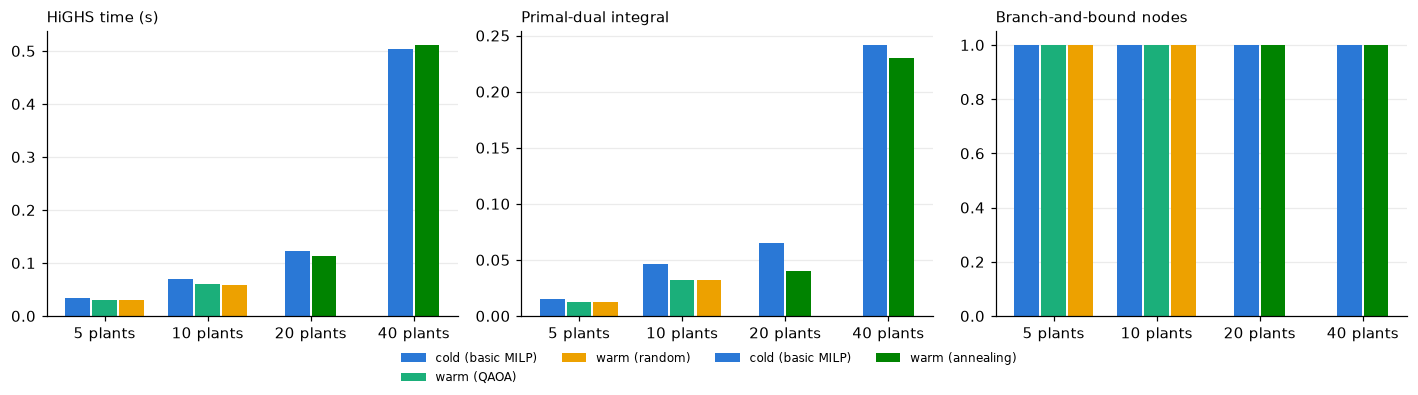

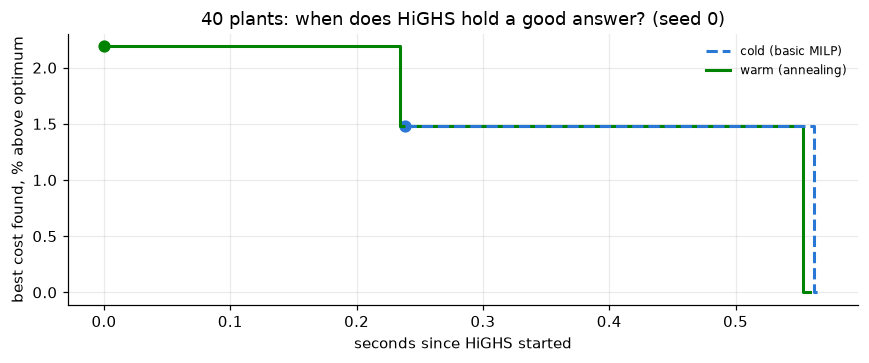

In [9]:
MODE_COLORS = {"cold (basic MILP)": COLORS["milp"], "warm (QAOA)": COLORS["warm"],
               "warm (random)": COLORS["random"], "warm (annealing)": COLORS["noisy"]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, key, title in [(axes[0], "seconds", "HiGHS time (s)"), (axes[1], "pdi", "Primal-dual integral"),
                       (axes[2], "nodes", "Branch-and-bound nodes")]:
    width = 0.26
    for ci, c in enumerate(cases):
        modes = list(c["runs"])
        for mi, mode in enumerate(modes):
            x = ci + (mi - (len(modes) - 1) / 2) * width
            ax.bar(x, med(c["runs"][mode], key), width * 0.92, color=MODE_COLORS[mode],
                   label=mode if ci in (0, 2) else None)
    ax.set_xticks(range(len(cases)), [c["label"] for c in cases])
    ax.set_title(title, fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=4, frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

# incumbent cost over time for the biggest case
c = cases[-1]
fig, ax = plt.subplots(figsize=(8, 3.4))
for mode, rs in c["runs"].items():
    r = rs[0]
    pts = list(r["timeline"])
    if mode != "cold (basic MILP)":
        pts = [(0.0, c["starts"][mode][1])] + pts            # the start is in hand at t = 0
    if not pts:
        continue
    ts = [p[0] for p in pts] + [r["seconds"]]
    gs = [100 * (p[1] - c["opt"]) / c["opt"] for p in pts]
    gs = gs + [gs[-1]]
    cold = mode.startswith("cold")
    ax.step(ts, gs, where="post", color=MODE_COLORS[mode], lw=2, ls="--" if cold else "-", label=mode,
            zorder=3 if cold else 2)
    ax.plot(ts[0], gs[0], "o", color=MODE_COLORS[mode], ms=7)
ax.set(xlabel="seconds since HiGHS started", ylabel="best cost found, % above optimum",
       title=f"{c['label']}: when does HiGHS hold a good answer? (seed {SEED})")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 7. Hardware next to the simulator

Hardware circuits must be short (IonQ advises a few dozen two-qubit gates), so for the device runs we use the smallest version of our QUBO: **5 plants × 2 blocks = 10 qubits, p = 1**. The angles are trained on the simulator, then the *same* circuit is measured on each backend with the same number of shots:

| Backend | What it is |
|---|---|
| exact statevector | the ideal probabilities (a curve, no shots) |
| Aer | noiseless simulator, `HW_SHOTS` shots |
| IonQ simulator + Forte-1 noise model | `ionq:ionq:sim:simulator`, free |
| Quantinuum H2 **emulator** | `quantinuum:quantinuum:sim:h2-emulator`, free, optional |
| IonQ Forte **QPU** | `QPU_DEVICE`, paid, optional |
| uniform random | the no-quantum control |

Each set of shots then goes through the same repair → warm start → HiGHS steps, so we can see what noise does to the answer.

In [10]:
from qiskit import transpile

K_HW = 2
blocks_hw = qw.split_into_blocks(demand + reserve, K_HW)
qubo_hw = qw.Qubo(plants, demand, reserve, blocks_hw)
tr_hw = train_qaoa(qubo_hw, p=1)
qc_hw = transpile(measured_circuit(qubo_hw, tr_hw), basis_gates=["h", "rx", "rz", "cx"], optimization_level=1)
ops = qc_hw.count_ops()
print(f"Blocks {[f'{h[0]}-{h[-1]}' for h in blocks_hw]} -> {qubo_hw.N} qubits, p=1, "
      f"angles gamma={tr_hw['gammas'].round(4).tolist()} beta={tr_hw['betas'].round(4).tolist()}")
print(f"Circuit for devices: {ops.get('cx', 0)} CX (two-qubit) gates, depth {qc_hw.depth()}, "
      f"CVaR(0.25) {tr_hw['cvar']:+.3f} vs {tr_hw['cvar_uniform']:+.3f} random")

CACHE = OUT / "hardware_runs.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
circuit_tag = {"qubits": qubo_hw.N, "blocks": [[h[0], h[-1]] for h in blocks_hw], "p": 1,
               "gammas": tr_hw["gammas"].round(6).tolist(), "betas": tr_hw["betas"].round(6).tolist()}


def device_counts(label, device_id, runtime_options=None):
    """Submit qc_hw once (or reuse the cached job), wait up to WAIT_S, return {int bitstring: count} or None."""
    from qbraid.runtime import QbraidProvider, QbraidJob
    rec = cache.get(label)
    if rec and rec.get("counts"):
        print(f"{label}: cached result of job {rec['job_id']}")
        return {int(k): v for k, v in rec["counts"].items()}
    if rec and rec.get("job_id") and rec.get("status") not in ("FAILED", "CANCELLED"):
        job = QbraidJob(rec["job_id"])                       # submitted earlier, maybe still queued
        print(f"{label}: checking earlier job {rec['job_id']}")
    else:
        device = QbraidProvider().get_device(device_id)
        status = str(device.status())
        if "ONLINE" not in status:
            print(f"{label}: {device_id} is {status}, skipped"); return None
        price = device.profile.pricing
        est = (float(price.perTask) + float(price.perShot) * HW_SHOTS) if price else 0.0
        per_min = float(price.perMinute) if price else 0.0
        print(f"{label}: {device_id}, estimated cost {est:,.0f} credits (${est / 100:,.2f})"
              + (f" + {per_min:g} credits/min" if per_min else ""))
        if est > MAX_CREDITS or per_min > 0:
            print(f"   NOT submitted: above MAX_CREDITS = {MAX_CREDITS}"); return None
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            job = device.run(qc_hw, shots=HW_SHOTS, **({"runtime_options": runtime_options} if runtime_options else {}))
        rec = cache[label] = {"device": device_id, "job_id": job.id, "shots": HW_SHOTS, "est_credits": est,
                              "runtime_options": runtime_options, "submitted": time.time(), "circuit": circuit_tag,
                              "cx": ops.get("cx", 0), "depth": qc_hw.depth()}
        CACHE.write_text(json.dumps(cache, indent=1))
        print(f"   submitted job {job.id} (watch it in the Quantum Jobs panel)")
    try:
        job.wait_for_final_state(timeout=WAIT_S)
    except Exception as e:                                   # still queued: keep the job id, come back later
        rec["status"] = str(job.status()).split(".")[-1]
        CACHE.write_text(json.dumps(cache, indent=1))
        print(f"   not finished after {WAIT_S} s ({rec['status']}); re-run this cell later"); return None
    rec["status"] = str(job.status()).split(".")[-1]
    if rec["status"] != "COMPLETED":
        CACHE.write_text(json.dumps(cache, indent=1)); print(f"   job ended {rec['status']}"); return None
    counts = {int(b.replace(" ", ""), 2): int(c) for b, c in job.result().data.get_counts().items()}
    rec["counts"] = {str(k): v for k, v in counts.items()}
    rec["finished"] = time.time()
    rec["wall_s"] = rec["finished"] - rec["submitted"]
    CACHE.write_text(json.dumps(cache, indent=1))
    print(f"   done: {len(counts)} distinct bitstrings, {rec['wall_s']:.0f} s from submission to result")
    return counts


backends = {"Aer (noiseless sim)": sample_aer(qc_hw, HW_SHOTS, SEED)}
if RUN_NOISY_SIM:
    backends["IonQ sim + Forte-1 noise"] = device_counts("IonQ sim + Forte-1 noise", "ionq:ionq:sim:simulator",
                                                         {"noise_model": "forte-1"})
if RUN_H2_EMULATOR:
    backends["Quantinuum H2 emulator"] = device_counts("Quantinuum H2 emulator", "quantinuum:quantinuum:sim:h2-emulator")
if RUN_QPU or (cache.get("IonQ Forte QPU", {}).get("job_id")):
    backends["IonQ Forte QPU"] = device_counts("IonQ Forte QPU", QPU_DEVICE)
backends["uniform random"] = sample_uniform(qubo_hw.N, HW_SHOTS, SEED)
backends = {k: v for k, v in backends.items() if v}

Blocks ['0-6', '7-23'] -> 10 qubits, p=1, angles gamma=[-1.4842] beta=[0.5806]
Circuit for devices: 50 CX (two-qubit) gates, depth 31, CVaR(0.25) -1.585 vs -1.085 random


IonQ sim + Forte-1 noise: cached result of job ionq:ionq:sim:simulator-842a-qjob-6af901e4c8f5265fb3f21de4


In [11]:
HW_COLORS = {"Aer (noiseless sim)": COLORS["warm"], "IonQ sim + Forte-1 noise": COLORS["noisy"],
             "Quantinuum H2 emulator": COLORS["h2"], "IonQ Forte QPU": COLORS["qpu"], "uniform random": COLORS["random"]}
hw = {}
for label, cnt in backends.items():
    a = analyze(cnt, qubo_hw, model, tr_hw["E"], MILP_COST)
    a["highs"] = run_highs(model, qw.full_solution(model, a["warm_S"]), seed=SEED)
    hw[label] = a

E_hw = tr_hw["E"]
ideal_p_opt = tr_hw["probs"][E_hw <= E_hw.min() + 1e-9].sum()
print(f"Exact statevector: P(QUBO optimum) = {ideal_p_opt:.2%}  (random guess: {2.0 ** -qubo_hw.N:.2%})\n")
print(f"{'backend':<27}{'shots':>6}{'P(opt)':>8}{'best 5%':>8}{'valid raw':>10}{'repairable':>11}{'CVaR':>8}"
      f"{'warm start':>12}{'gap':>8}{'HiGHS final':>13}")
for label, a in hw.items():
    print(f"{label:<27}{a['shots']:>6}{a['p_opt']:>8.1%}{a['low5']:>8.1%}{a['raw_valid']:>10.1%}{a['repairable']:>11.1%}"
          f"{a['cvar25']:>+8.3f}  ${a['warm_cost']:>10,.0f}{a['warm_gap']:>+7.2f}%  ${a['highs']['objective']:>10,.0f}")

print("\nRun record")
print(f"{'backend':<27}{'device':<40}{'job id':<62}{'status':<11}{'credits':>8}{'wait+run s':>11}")
for label in hw:
    rec = cache.get(label)
    if rec:
        print(f"{label:<27}{rec['device']:<40}{rec['job_id']:<62}{rec.get('status', '?'):<11}"
              f"{rec['est_credits']:>8.0f}{rec.get('wall_s', float('nan')):>11.0f}")
    else:
        print(f"{label:<27}{'local (this Lab instance)':<40}{'-':<62}{'-':<11}{0:>8}{'-':>11}")

Exact statevector: P(QUBO optimum) = 0.81%  (random guess: 0.10%)

backend                     shots  P(opt) best 5% valid raw repairable    CVaR  warm start     gap  HiGHS final
Aer (noiseless sim)           200    1.0%   34.0%      0.0%     100.0%  -1.559  $   331,596  +1.12%  $   327,924
IonQ sim + Forte-1 noise      200    1.0%   22.0%      0.0%     100.0%  -1.544  $   331,596  +1.12%  $   327,924
uniform random                200    0.0%    4.0%      0.0%     100.0%  -1.083  $   331,596  +1.12%  $   327,924

Run record
backend                    device                                  job id                                                        status      credits wait+run s
Aer (noiseless sim)        local (this Lab instance)               -                                                             -                 0          -
IonQ sim + Forte-1 noise   ionq:ionq:sim:simulator                 ionq:ionq:sim:simulator-842a-qjob-6af901e4c8f5265fb3f21de4    COMPLETED         0  

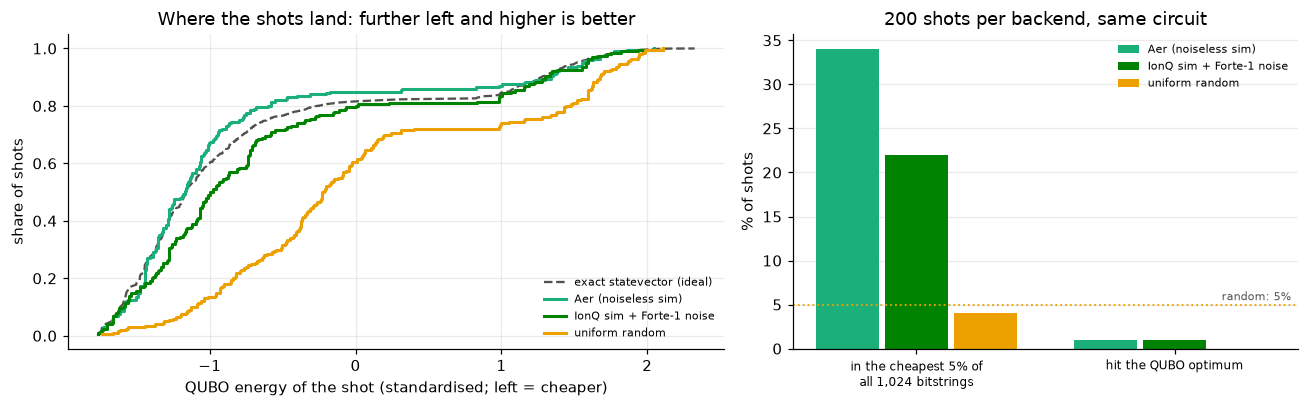

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
Ehat_hw = (E_hw - E_hw.mean()) / E_hw.std()
order = np.argsort(Ehat_hw)
axes[0].plot(Ehat_hw[order], np.cumsum(tr_hw["probs"][order]), color="#52514e", lw=1.5, ls="--",
             label="exact statevector (ideal)")
for label, cnt in backends.items():
    e = np.sort(np.repeat([Ehat_hw[z] for z in cnt], list(cnt.values())))
    axes[0].step(e, np.arange(1, len(e) + 1) / len(e), where="post", color=HW_COLORS[label], lw=2, label=label)
axes[0].set(xlabel="QUBO energy of the shot (standardised; left = cheaper)", ylabel="share of shots",
            title="Where the shots land: further left and higher is better")
axes[0].legend(fontsize=7, frameon=False, loc="lower right")

metrics = [("low5", "in the cheapest 5% of\nall 1,024 bitstrings"), ("p_opt", "hit the QUBO optimum")]
width = 0.8 / len(hw)
for bi, (label, a) in enumerate(hw.items()):
    xs = np.arange(len(metrics)) + (bi - (len(hw) - 1) / 2) * width
    axes[1].bar(xs, [100 * a[k] for k, _ in metrics], width * 0.92, color=HW_COLORS[label], label=label)
axes[1].set_xticks(range(len(metrics)), [m for _, m in metrics], fontsize=8)
axes[1].set(ylabel="% of shots", title=f"{HW_SHOTS} shots per backend, same circuit")
axes[1].axhline(5, color=COLORS["random"], ls=":", lw=1.2)
axes[1].text(1.45, 5.5, "random: 5%", fontsize=7, color="#52514e", ha="right")
axes[1].legend(fontsize=7, frameon=False)
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 8. Summary in numbers

The cell below prints the headline numbers for the slides from this run.

In [13]:
c5 = cases[0]
cold_t = med(c5["runs"]["cold (basic MILP)"], "seconds")
warm_t = med(c5["runs"]["warm (QAOA)"], "seconds")
print(f"Exact MILP optimum (5 plants, 24 h): ${MILP_COST:,.0f}/day, solved in {cold0['seconds']:.2f} s at {cold0['nodes']} node(s).")
print(f"Cheapest-first rule: ${RULE_COST:,.0f}/day ({rule_r['gap_pct']:+.2f}%), {len(rule_r['violations'])} rule(s) broken.")
d = qa['warm_cost'] - RULE_COST
print(f"QAOA + repair warm start: ${qa['warm_cost']:,.0f}/day ({qa['warm_gap']:+.2f}%), 0 rules broken; "
      f"${abs(d):,.0f}/day {'cheaper' if d < 0 else 'more expensive'} than the (rule-breaking) cheapest-first rule.")
print(f"Random + repair warm start (same shots): ${ra['warm_cost']:,.0f}/day ({ra['warm_gap']:+.2f}%).")
print(f"Final answer after warm-started HiGHS: ${warm0['objective']:,.0f} = the optimum. 0 rules broken.")
print(f"Valid as sampled: QAOA {qa['raw_valid']:.1%} of shots vs random {ra['raw_valid']:.1%}; "
      f"after repair: {qa['repairable']:.1%} vs {ra['repairable']:.1%}.")
print(f"HiGHS, 5 plants: cold {cold_t:.3f} s vs warm {warm_t:.3f} s (median of {REPEATS}); "
      f"P-D integral {med(c5['runs']['cold (basic MILP)'], 'pdi'):.4f} -> {med(c5['runs']['warm (QAOA)'], 'pdi'):.4f}.")
print(f"Quantum step (simulated, 20 qubits): {c5['quantum_s']:.1f} s; that alone is ~{c5['quantum_s'] / cold_t:,.0f}x the cold MILP time.")
for label, a in hw.items():
    rec = cache.get(label, {})
    extra = f", job {rec['job_id']}, {rec.get('wall_s', 0):.0f} s incl. queue" if rec else ""
    print(f"  {label}: P(opt) {a['p_opt']:.1%}, cheapest-5% share {a['low5']:.0%}, valid raw {a['raw_valid']:.1%}, warm start {a['warm_gap']:+.2f}%{extra}")

Exact MILP optimum (5 plants, 24 h): $327,924/day, solved in 0.03 s at 1 node(s).
Cheapest-first rule: $330,594/day (+0.81%), 1 rule(s) broken.
QAOA + repair warm start: $331,596/day (+1.12%), 0 rules broken; $1,002/day more expensive than the (rule-breaking) cheapest-first rule.
Random + repair warm start (same shots): $331,596/day (+1.12%).
Final answer after warm-started HiGHS: $327,924 = the optimum. 0 rules broken.
Valid as sampled: QAOA 2.4% of shots vs random 0.1%; after repair: 100.0% vs 100.0%.
HiGHS, 5 plants: cold 0.034 s vs warm 0.030 s (median of 5); P-D integral 0.0148 -> 0.0125.
Quantum step (simulated, 20 qubits): 8.7 s; that alone is ~255x the cold MILP time.
  Aer (noiseless sim): P(opt) 1.0%, cheapest-5% share 34%, valid raw 0.0%, warm start +1.12%
  IonQ sim + Forte-1 noise: P(opt) 1.0%, cheapest-5% share 22%, valid raw 0.0%, warm start +1.12%, job ionq:ionq:sim:simulator-842a-qjob-6af901e4c8f5265fb3f21de4, 16 s incl. queue
  uniform random: P(opt) 0.0%, cheapest-5%

### What this means (numbers from the run saved in this notebook)

- **Cost.** QAOA + repair gives a legal schedule at **$331,596/day, +1.12%** above the optimum ($327,924). HiGHS then returns the exact optimum from that start, so the final answer is never worse than basic MILP. The cheapest-first rule, ranked as the README specifies, costs less (+0.81%) but **breaks a rule** (PEAKER_B switched off after 2 h, min up is 3 h). Ranked as `starter.ipynb` does, it costs +13.80% and breaks 2 rules. The raw QAOA sample looks *cheaper* than the optimum (−4.39%) only because it has too little capacity on in 6 hours: cheap because illegal.
- **Validity.** Only **2.4%** of raw QAOA shots obey every rule as sampled (random guessing: 0.1%). Min up/down times are not in the QUBO, and a plant can't switch mid-block. Repair makes **100%** of shots legal, *including random ones*, so "valid" is mostly repair's work.
- **Does QAOA matter?** At 4,000 shots, random + repair finds the same +1.12% start, so at that shot count QAOA adds nothing to the final start. With few shots it does help: at 20–1,000 shots the median QAOA start is +1.8–3.0% vs +4.4–6.0% for random (section 3 chart). QAOA's samples concentrate at low QUBO energy (CVaR −2.40 vs −1.25).
- **Speed.** Every instance, even 40 plants, is solved at the root node (1 node), so there is no search tree for a warm start to prune. The warm start lowers the primal-dual integral by 3–39% (5 plants 10%, 10 plants 29%, 20 plants 39%, 40 plants 3%) (a good answer is in hand from second zero), but HiGHS time changes are within noise. The simulated quantum step (≈8 s at 20 qubits) costs ~240× the cold MILP time. End to end, basic MILP is faster here.
- **Hardware vs simulator.** On the 10-qubit, 50-CX hardware circuit, the IonQ Forte-1 noisy simulator stays close to the noiseless one: 34% of noiseless shots and 22% of noisy shots land in the cheapest 5% of all 1,024 bitstrings, against 4% for random guessing. Both lead to the same +1.12% warm start and the same final optimum. Its job ran in about 16 s. **No real-QPU run has been done yet**: `RUN_QPU = False`. At 200 shots, `aws:ionq:qpu:forte-1` is estimated at about 1,630 credits, and the account had about 1,185 when this was built. Fewer shots (≤140) would fit, or use the free noisy simulator result as the stand-in and say so.
- **What would have to change.** A MILP that HiGHS cannot close at the root (ramp limits, longer horizons, many near-identical units, network constraints), and QPUs large and clean enough to sample the full commitment problem without blocks, with queue times in seconds rather than minutes.